## IA DATASET ANALISIS ##

In [ ]:
import pandas as pd
import numpy as np
%pip install missingno
import missingno as msno
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
#Le damos formato y estilo a los graficos del matplolib y seaborn
sns.set_theme(style = "whitegrid", palette = "viridis", font_scale = 1.1)

In [ ]:
#Configuramos para que en todos los graficos aparezcan todas las columnas que solicitamos
pd.set_option('display.max_columns', None)

In [ ]:
# Se carga el dataset en crudo#
df = pd.read_csv('ai_agent_incidents.csv', sep=',', encoding = 'utf-8')
df_copy= df
df

In [ ]:
#Reaslizamos un .shape para ver dimensiones(Rows, Columns)
print(df.shape)

In [28]:
#Verificam,os primeros datos del dataset con un head
df.head(20)

,id_incidente,fecha,anio,codigo_ataque,attack_type_name,tipo_registro,gravedad,nivel_confianza,dano_real_confirmado,participacion_ia,codigo_region,evento_emblematico,source_count,n_tipos_ataque,ataque_robo_credenciales,ataque_manipulacion_evaluaciones,ataque_fuga_datos_modelos,ataque_fallo_gobernanza,ataque_infraestructura,ataque_inyeccion_prompt_indirecta,ataque_explotacion_mcp,ataque_otro_no_clasificado,ataque_agente_autonomo_rebelde,ataque_escape_sandbox,ataque_cadena_suministro,ataque_uso_malicioso_ia,n_regiones,region_asia_pacifico,region_australia,region_china,region_ue,region_global,region_hong_kong,region_japon,region_corea_sur,region_latam,region_sudeste_asiatico,region_taiwan,region_reino_unido,region_eeuu,gravedad_num,nivel_confianza_num,participacion_ia_confirmada,mes_num,trimestre,dia_semana,dias_desde_inicio,anio_mes
0,2024-12-01-storm-azure-llmjacking,2024-12-01,2024,CRED,Credential & Secret Theft,incident,high,a,1,confirmed,GLOBAL,0,1,1,1,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,1,0,0,0,0,0,0,0,0,3,4,1,12,4,6,0,2024-12
1,2025-01-01-maine-town-deepfake-phishing,2025-01-01,2025,OTHER,Unclassified AI Incident,incident,medium,a,1,confirmed,US,0,1,1,0,0,0,0,0,0,0,1,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,1,2,4,1,1,1,2,31,2025-01
2,2025-01-20-hk-voice-clone-usdt-fraud,2025-01-20,2025,OTHER,Unclassified AI Incident,incident,medium,a,1,confirmed,HK,0,1,1,0,0,0,0,0,0,0,1,0,0,0,0,1,0,0,0,0,0,1,0,0,0,0,0,0,0,2,4,1,1,1,0,50,2025-01
3,2025-01-26-harbin-asian-winter-games-attack,2025-01-26,2025,WEAPON,AI Weaponization & Malicious Tooling,incident,high,d,1,disputed,CN,0,1,1,0,0,0,0,0,0,0,0,0,0,0,1,1,0,0,1,0,0,0,0,0,0,0,0,0,0,3,1,0,1,1,6,56,2025-01
4,2025-01-27-deepseek-zao-gui-mo-gong,2025-01-27,2025,OTHER,Unclassified AI Incident,incident,medium,b,1,confirmed,CN,0,1,1,0,0,0,0,0,0,0,1,0,0,0,0,1,0,0,1,0,0,0,0,0,0,0,0,0,0,2,3,1,1,1,0,57,2025-01
5,2025-01-29-deepseek-clickhouse-exposed,2025-01-29,2025,INFRA,AI Infrastructure & Cluster Compromise,incident,critical,a,1,confirmed,CN,1,1,1,0,0,0,0,1,0,0,0,0,0,0,0,1,0,0,1,0,0,0,0,0,0,0,0,0,0,4,4,1,1,1,2,59,2025-01
6,2025-01-31-github-copilot-shuang-lou-dong,2025-01-31,2025,SANDBOX,Sandbox & Environment Escape,vulnerability,medium,b,0,confirmed,GLOBAL,0,1,1,0,0,0,0,0,0,0,0,0,1,0,0,1,0,0,0,0,1,0,0,0,0,0,0,0,0,2,3,1,1,1,4,61,2025-01
7,2025-02-01-ollama-fu-wu-qi-gui,2025-02-01,2025,INFRA,AI Infrastructure & Cluster Compromise,incident,high,a,1,confirmed,CN;GLOBAL,0,1,1,0,0,0,0,1,0,0,0,0,0,0,0,2,0,0,1,0,1,0,0,0,0,0,0,0,0,3,4,1,2,1,5,62,2025-02
8,2025-02-06-hugging-face-nullifai,2025-02-06,2025,SUPPLY,AI Supply Chain & Dependency Attack,incident,high,a,0,confirmed,GLOBAL,0,1,1,0,0,0,0,0,0,0,0,0,0,1,0,1,0,0,0,0,1,0,0,0,0,0,0,0,0,3,4,1,2,1,3,67,2025-02
9,2025-02-11-omnigpt-shu-ju-xie-lu,2025-02-11,2025,OTHER,Unclassified AI Incident,incident,medium,b,1,confirmed,GLOBAL,0,1,1,0,0,0,0,0,0,0,1,0,0,0,0,1,0,0,0,0,1,0,0,0,0,0,0,0,0,2,3,1,2,1,1,72,2025-02


In [ ]:
#Realizamos un tail para verificar el final del dataset
df.tail(20)

### Nulos y Duplicados ###

Nulos totales en df: 0
Forma: (395, 17)
Duplicados Totales: 0
IDs duplicados: 0


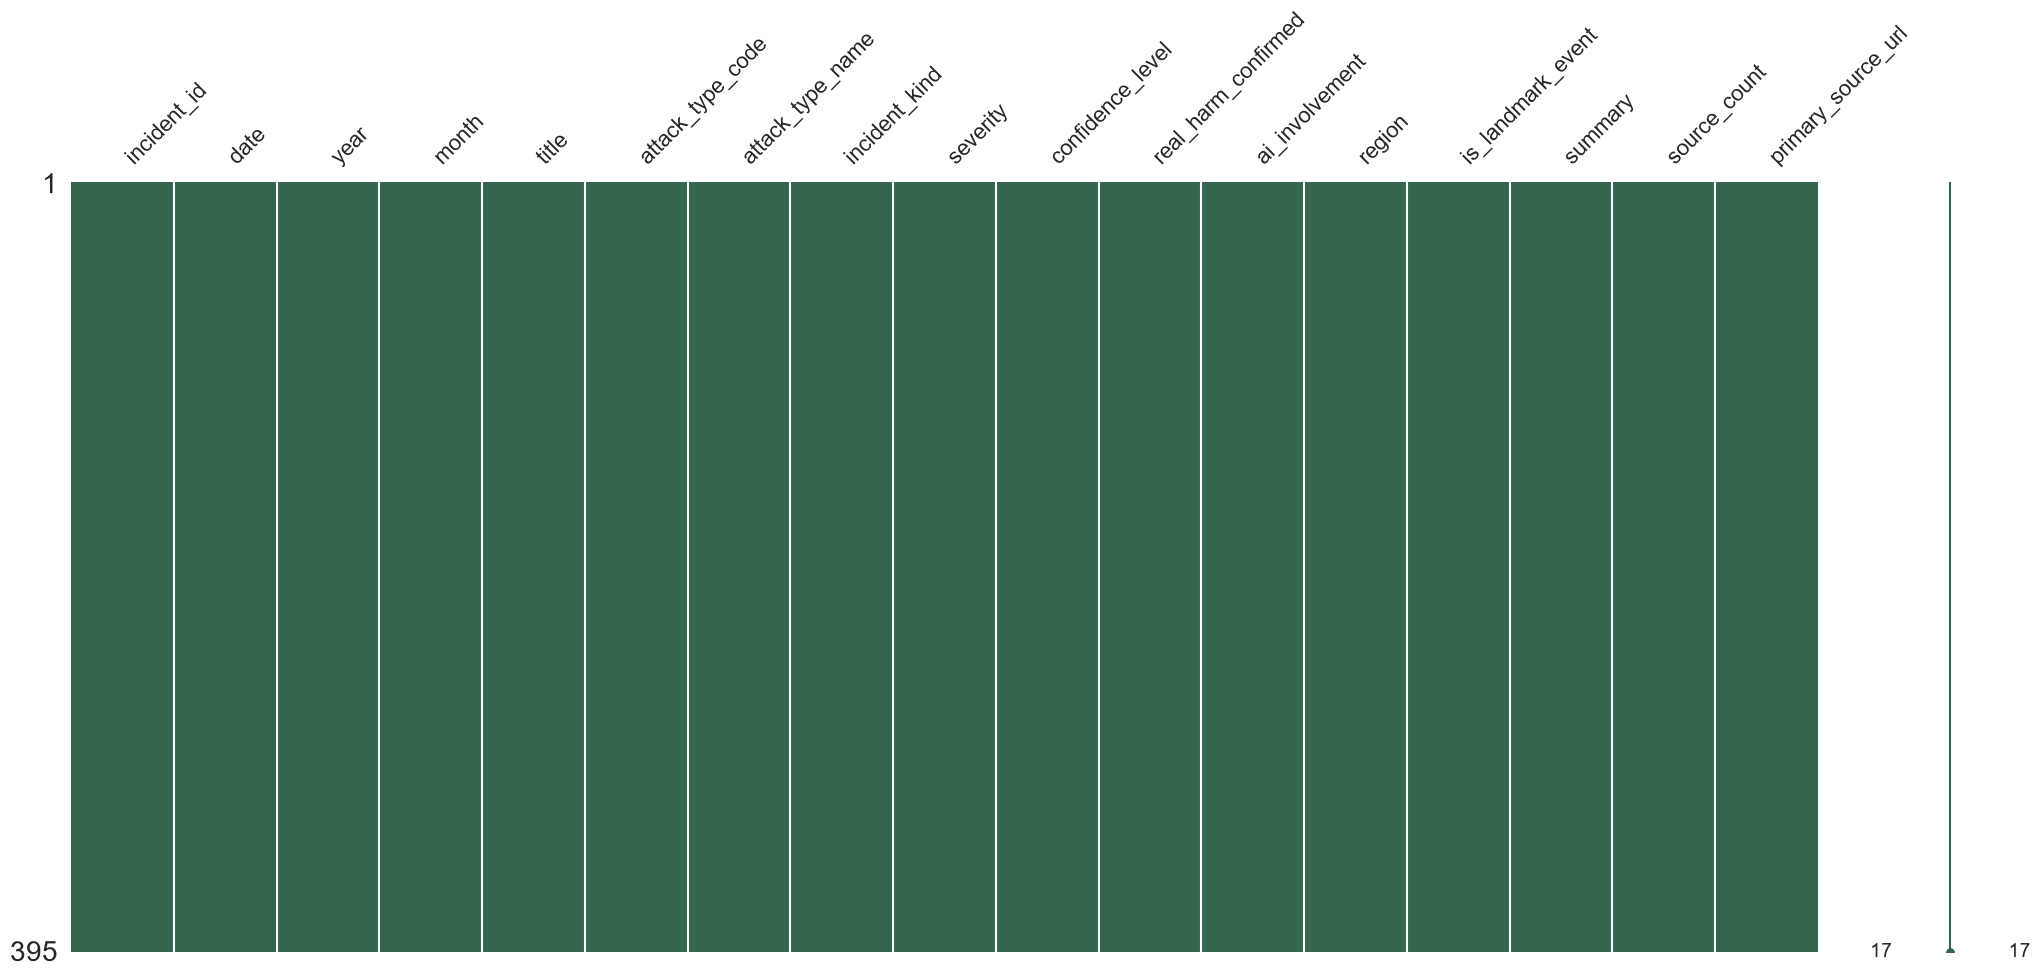

In [8]:
#Vamos a analizar la cantidad de datos nulos y duplicados
print("Nulos totales en df:", df.isnull().sum().sum())
print("Forma:", df.shape) 
print("Duplicados Totales:", df.duplicated().sum())
print("IDs duplicados:", df["incident_id"].duplicated().sum())

msno.matrix(df, color=(0.2, 0.4, 0.3))
plt.show()


#No cuenta con datos duplicados ni con datos nulos

### Tipos y Texto ###

In [9]:
# Vamor a tranformar las variables de texto a tipo fecha para poder trabajar con ellas al igual que las que se necesiten transformar a numero entero
df["date"] = pd.to_datetime(df["date"], errors = "coerce") #Tipo de dato a fecha coerce para que si hay algun error lo transforme a NaT
df["real_harm_confirmed"] = df["real_harm_confirmed"].astype("int") #Convertimos a entero la variable real_harm_confirmed
df["is_landmark_event"] = df["is_landmark_event"].astype("int") #Convertimos a entero la variable is_landmark_event


for c in ["incident_kind", "severity", "confidence_level", "ai_involvement" ]:
    df[c] = df[c].str.strip() .str.lower() #Eliminamos espacios y pasamos a minusculas las variables de texto
for c in ["attack_type_code", "region"]:
    df[c] = df[c].str.strip() .str.upper() #Eliminamos espacios y pasamos a mayusculas las variables de texto

### Tipo de ataque ###

In [10]:
df["attack_list"] = df["attack_type_code"].str.split(";") #Dividimos los tipos de ataque por punto y coma
df["n_attack_types"] = df["attack_list"].str.len() # Creamos una nueva columna con la cantidad de tipos de ataque que tiene cada incidente
atk = df["attack_list"].explode().str.strip()# Explode para separar los tipos de ataque en filas y eliminar espacios, el explode expande los elementos de una lista en una fila separada cada uno
atk_dummies = (pd.crosstab(atk.index, atk).clip(upper=1) # Creamos una tabla de contingencia con crosstab, clip para que los valores sean 0 o 1, crosstab crea una tabla cruzada y mide la realcion entre dos variables categoricas
               .add_prefix("atk_").astype(int)) # Agregamos un prefijo a las columnas y convertimos a entero
df = df.join(atk_dummies) # Unimos las variables dummy al DataFrame original

### Regiones ###

In [11]:
df["region_list"] = df["region"].str.split(";") #Dividimos las regiones por punto y coma
df["n_regions"] = df["region_list"].str.len() # Creamos una nueva columna con la cantidad de regiones que tiene cada incidente
reg = df["region_list"].explode().str.strip()# Explode para separar las regiones en filas y eliminar espacios, el explode expande los elementos de una lista en una fila separada cada uno
reg_dummies = (pd.crosstab(reg.index, reg).clip(upper=1) # Creamos una tabla de contingencia con crosstab, clip para que los valores sean 0 o 1, crosstab crea una tabla cruzada y mide la realcion entre dos variables categoricas
               .add_prefix("reg_").astype(int)) # Agregamos un prefijo a las columnas y convertimos a entero
df = df.join(reg_dummies) # Unimos las variables dummy al DataFrame original

### Categorias ordenadas a numeros ###

In [12]:
df["severity_ord"] = df["severity"].map( # Creamos una nueva columna con la severidad en orden de importancia
    {"info": 0, "low": 1, "medium": 2, "high": 3, "critical": 4}) # Transforma cada palabra clave en un numero entero
df["confidence_ord"] = df["confidence_level"].map( # Creamos una nueva columna con la confianza en orden de importancia
    {"d": 1, "c": 2, "b": 3, "a": 4})        # supuesto: a = más confiable #Lo mismo solo que dejamos la a como la mayor en este caso
df["ai_confirmed"] = (df["ai_involvement"] == "confirmed").astype(int) #Confirmamos si IA tuvo participacion

### Variables a tiempo ###

In [13]:
df["month_num"] = df["date"].dt.month #Tranformamos el mes en la variable en formato mes
df["quarter"] = df["date"].dt.quarter 
df["dayofweek"] = df["date"].dt.dayofweek
df["days_since_start"] = (df["date"] - df["date"].min()).dt.days #Convertimos el dia de inicio filtrando el minimo en la fecha de cada incidente
df["year_month"] = df["date"].dt.to_period("M").astype(str) #Convertimos en texto el mes de la fecha

### Columnas de referencia y eliminacion ###

In [14]:
referencia = df[["incident_id", "title", "summary", # Pedimos una lista de las columnas y se guardan en una tabla llamada referencias
                 "primary_source_url", "attack_type_name"]].copy() # copy() hace una copia independiente

df = df.drop(columns=["title", "summary", "primary_source_url", #Quita las columnas y devuelve el dataframe sin esas columnas
                      "attack_list", "region_list", "month"])

### Validacion y guardado ###

In [ ]:
print("\nForma final:", df.shape) # Nos muestra el dataset final despues de la limpieza
print("Nulos:", df.isnull().sum().sum()) # Imprime la cantidad de los nulos
print("Duplicados:", df.duplicated().sum()) # Imprime la cantidad de duplicados
print(df.dtypes.value_counts()) # Devuelve los tipos de datos y la cantidad de cada uno

df.to_csv("incidentes_limpio.csv", index=False) #Convierte el df nuevo en csv
referencia.to_csv("incidentes_referencia.csv", index=False) #Nombre del csv original 

### Renombramiento de Variables

In [15]:
df = pd.read_csv("incidentes_limpio.csv")
referencia = pd.read_csv("incidentes_referencia.csv")

#Columnas principales y derivadas
base = {
    "incident_id": "id_incidente", "date": "fecha", "year": "anio",
    "year_month": "anio_mes", "month_num": "mes_num", "quarter": "trimestre",
    "dayofweek": "dia_semana", "days_since_start": "dias_desde_inicio",
    "attack_type_code": "codigo_ataque", "n_attack_types": "n_tipos_ataque",
    "incident_kind": "tipo_registro", "severity": "gravedad",
    "severity_ord": "gravedad_num", "confidence_level": "nivel_confianza",
    "confidence_ord": "nivel_confianza_num",
    "real_harm_confirmed": "dano_real_confirmado",
    "ai_involvement": "participacion_ia", "ai_confirmed": "participacion_ia_confirmada",
    "region": "codigo_region", "n_regions": "n_regiones",
    "is_landmark_event": "evento_emblematico",
}

#Las 12 columnas de tipo de ataque
ataques = {
    "CRED": "robo_credenciales", "EVAL": "manipulacion_evaluaciones",
    "EXFIL": "fuga_datos_modelos", "GOV": "fallo_gobernanza",
    "INFRA": "infraestructura", "IPI": "inyeccion_prompt_indirecta",
    "MCP": "explotacion_mcp", "OTHER": "otro_no_clasificado",
    "ROGUE": "agente_autonomo_rebelde", "SANDBOX": "escape_sandbox",
    "SUPPLY": "cadena_suministro", "WEAPON": "uso_malicioso_ia",
}

#Las 13 columnas de región 
regiones = {
    "GLOBAL": "global", "US": "eeuu", "CN": "china", "EU": "ue",
    "LATAM": "latam", "JP": "japon", "KR": "corea_sur", "AU": "australia",
    "HK": "hong_kong", "SEA": "sudeste_asiatico", "UK": "reino_unido",
    "TW": "taiwan", "APAC": "asia_pacifico",
}
#Agregan al diccionario base las equivalencias de las 25 columnas de ataque y region
base.update({f"atk_{k}": f"ataque_{v}" for k, v in ataques.items()})
base.update({f"reg_{k}": f"region_{v}" for k, v in regiones.items()})

df = df.rename(columns=base) #Renombramos la tabla principal
referencia = referencia.rename(columns={ #Renombramos la tabla de referencia
    "incident_id": "id_incidente", "title": "titulo", "summary": "resumen",
    "primary_source_url": "url_fuente", "attack_type_name": "nombre_tipo_ataque",
})

#Comprobaciones
print("Sin renombrar:", [c for c in df.columns if c in base])   
print("Forma df:", df.shape)                                    
print("Forma referencia:", referencia.shape)                     
print(df.columns.tolist())

df.to_csv("incidentes_limpio_es.csv", index=False)
referencia.to_csv("incidentes_referencia_es.csv", index=False) 

Sin renombrar: []
Forma df: (395, 48)
Forma referencia: (395, 5)
['id_incidente', 'fecha', 'anio', 'codigo_ataque', 'attack_type_name', 'tipo_registro', 'gravedad', 'nivel_confianza', 'dano_real_confirmado', 'participacion_ia', 'codigo_region', 'evento_emblematico', 'source_count', 'n_tipos_ataque', 'ataque_robo_credenciales', 'ataque_manipulacion_evaluaciones', 'ataque_fuga_datos_modelos', 'ataque_fallo_gobernanza', 'ataque_infraestructura', 'ataque_inyeccion_prompt_indirecta', 'ataque_explotacion_mcp', 'ataque_otro_no_clasificado', 'ataque_agente_autonomo_rebelde', 'ataque_escape_sandbox', 'ataque_cadena_suministro', 'ataque_uso_malicioso_ia', 'n_regiones', 'region_asia_pacifico', 'region_australia', 'region_china', 'region_ue', 'region_global', 'region_hong_kong', 'region_japon', 'region_corea_sur', 'region_latam', 'region_sudeste_asiatico', 'region_taiwan', 'region_reino_unido', 'region_eeuu', 'gravedad_num', 'nivel_confianza_num', 'participacion_ia_confirmada', 'mes_num', 'trimest

## EDA 

### Carga y filtro del dataset

In [16]:
# Filtramos para quitar las columnas policy y report
sns.set_theme(style="whitegrid", palette="viridis", font_scale=1.1)
pd.set_option("display.max_columns", None)

df = pd.read_csv("incidentes_limpio_es.csv", parse_dates=["fecha"])
print("Antes del filtro:", df.shape)

# Quitamos policy y report
df = df[~df["tipo_registro"].isin(["policy", "report"])].reset_index(drop=True)
print("Después del filtro:", df.shape)       

atk_cols = [c for c in df.columns if c.startswith("ataque_")]
reg_cols = [c for c in df.columns if c.startswith("region_")]
orden_grav = ["low", "medium", "high", "critical"] #Acomodamos los valores por su nivel critico

Antes del filtro: (395, 48)
Después del filtro: (308, 48)


Se realizó un filtro donde se omitieron valores con el tipo de registro "policy" y "report", podemos observar el primer dato que nos da las columnas y registros antes del filtro y despues cuantos valores hay despues de que aplicamos el filtro

### Panorama general

In [17]:
#Se imprimen las caracteristicas reales de cada variable del dataset y sus medidas 
df.info()

print(df[["gravedad_num", "dano_real_confirmado", "n_tipos_ataque", #Imprimimos la informacion de estas 4 variables
          "n_regiones", "nivel_confianza_num"]].describe().round(2))

for c in ["tipo_registro", "gravedad", "participacion_ia", "nivel_confianza"]:
    print(f"\n{c}")
    print(df[c].value_counts()) #Realizamos el conteo de estas variables binarias para sacar una estadistica completa

print("\nDaño real confirmado:", df["dano_real_confirmado"].sum(),
      f"({df['dano_real_confirmado'].mean():.1%})") #Sacamos el porcentaje del daño causado

<class 'pandas.DataFrame'>
RangeIndex: 308 entries, 0 to 307
Data columns (total 48 columns):
 #   Column                             Non-Null Count  Dtype         
---  ------                             --------------  -----         
 0   id_incidente                       308 non-null    str           
 1   fecha                              308 non-null    datetime64[us]
 2   anio                               308 non-null    int64         
 3   codigo_ataque                      308 non-null    str           
 4   attack_type_name                   308 non-null    str           
 5   tipo_registro                      308 non-null    str           
 6   gravedad                           308 non-null    str           
 7   nivel_confianza                    308 non-null    str           
 8   dano_real_confirmado               308 non-null    int64         
 9   participacion_ia                   308 non-null    str           
 10  codigo_region                      308 non-null  

Podemos observar las variables y sus tipos de datos, es importante destacar que en su mayoria tenemos incidentes con 162 incidentes en total, seguidamente las investigaciones y por ultimo vulnerabilidades. Tenemos 157 incidentes de gravedad alta liderando la lista por una gran diferencia ya que las de gravedad media que son la siguiente categoria con mas registros apenas contiene 94 registros, es importante destacar que apenas 9 de esos registros equivalen a incidentes de gravedad baja. En su gran mayoria de registros contamos con participacion de la ia con 299 participaciones y apenas 2 ocasiones en las que no se participo.

Podemos concluir que el daño real confirmado es de un 45.8% del dataset.

### Gravedad, tipo de registro y daño real

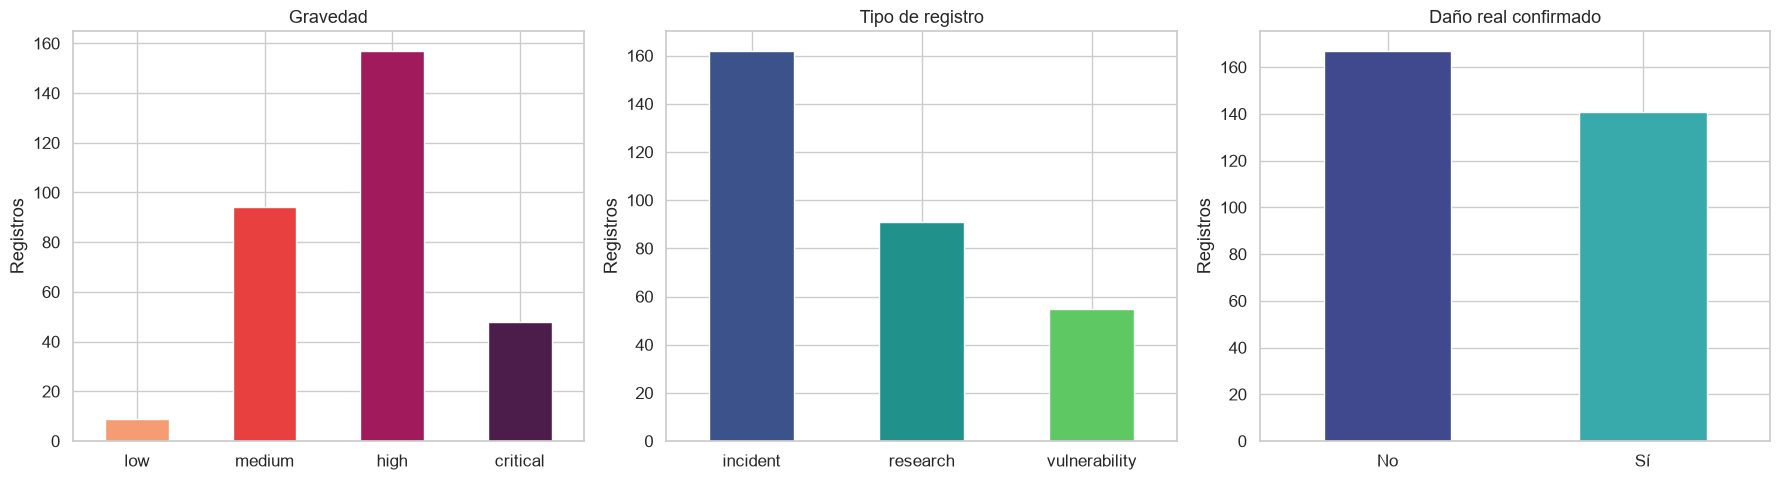

In [18]:
#Creamos graficos que van a medir 3 variables, gravedad, tipo de registro y daño real confirmado
fig, ax = plt.subplots(1, 3, figsize=(18, 5)) #Tamaño de cada grafico y orden de los sub graficos

g = df["gravedad"].value_counts().reindex(orden_grav) #Cuenta cada columna de gravedad y los ordena
g.plot(kind="bar", ax=ax[0], color=sns.color_palette("rocket_r", len(g))) #Estilo de grafico
ax[0].set_title("Gravedad") #Definimos el titulo

t = df["tipo_registro"].value_counts() #Cuenta los registros de la variable tipo_registro 
t.plot(kind="bar", ax=ax[1], color=sns.color_palette("viridis", len(t)))#Estilo de grafico
ax[1].set_title("Tipo de registro")#Definimos el titulo

d = df["dano_real_confirmado"].map({0: "No", 1: "Sí"}).value_counts() #Mapeamos ordenando el 0 como no y el 1 como si y acomodandolos con base a su suma
d.plot(kind="bar", ax=ax[2], color=sns.color_palette("mako", len(d))) #Estilo de grafico
ax[2].set_title("Daño real confirmado") #Definimos titulo

for a in ax:
    a.set_xlabel("") #Borra el texto horizontal del eje
    a.set_ylabel("Registros") #Coloca el texto en la parte vertical
    a.tick_params(axis="x", rotation=0) #Deja horizontales los nombres de las categorías del eje X
plt.tight_layout() #Evita que los titulos y barras se interpongan entre si
plt.show() #Muestra el resultado

Analizamos las variables gravedad, tipo de registro y daño real confirmado, en la variable gravedad vemos que en la mayoria de registros son de la categoria "high" con casi 160 regustros, seguidamente vemos la categoria "medium" con casi 100 registros, en el tercer puesto vemos la categoria "critical" con poco mas de 40 registros y por ultimo vemos la categoria "low" con menos de 20 registros, podemos deducir que el dataset registra en su mayoria casos graves y no tanto de bajo nivel.

En la variable Tipo de Registro vemos 3 categorias, la categoria "incident", "research" y "vulnerability", esta lista la lidera la categoria "incident" con poco más de 160 registros, vemos una gran diferencia de cantidad de registros con respecto a la segunda categoria "research" con casi la mitad menos de registros, llegando aproximadamente a 90 registros, despues de tercero tenemos la categoria "vulnerability" con poco mas de 50 registros.

La tercer variable analizamos el daño real confirmado en este caso con 2 categorias "Si", "No", lidera la categoria "No" con más de 160 registros, despues sigue la categoria "Si" con 140 registros aproximadamente.

### Tipos de ataque

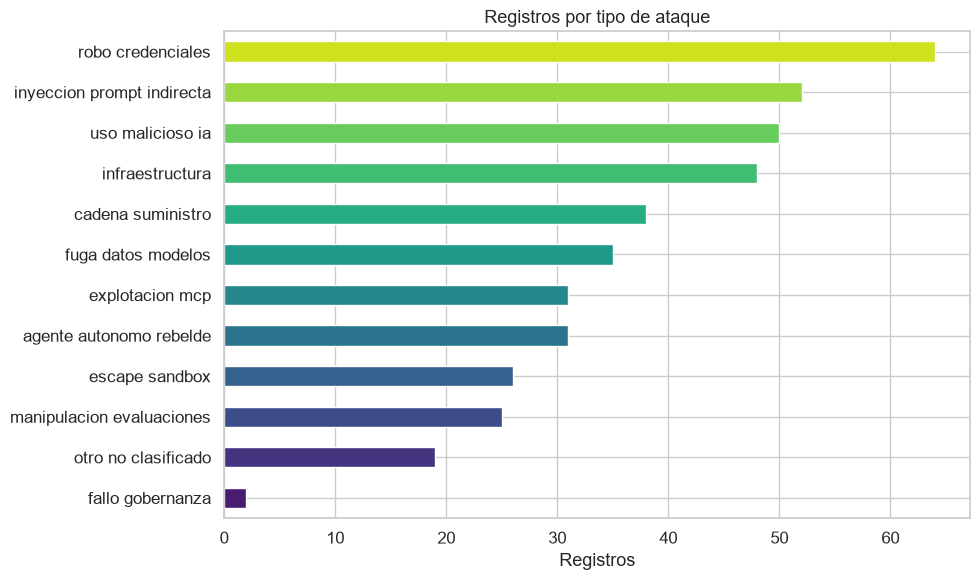

Tipos de ataque por registro:
n_tipos_ataque
1    198
2    107
3      3
Name: count, dtype: int64


In [19]:
frec = df[atk_cols].sum().sort_values() # Sumamos los registros de cada categoria de ataques, el comando sort_values() permite acomodar por valores ascendentes o descendentes 
frec.index = frec.index.str.replace("ataque_", "").str.replace("_", " ") #Limpiamos los nombres para que aparezcan mejor para el publico, el frec.index.str.replace("ataque_", "") borra el prefijo "ataque_"
#El str.replace("_", " ") remplaza los guiones bajos por espacios
frec.plot(kind="barh", figsize=(10, 6), color=sns.color_palette("viridis", len(frec)))
plt.title("Registros por tipo de ataque")
plt.xlabel("Registros")
plt.tight_layout()
plt.show()

print("Tipos de ataque por registro:")
print(df["n_tipos_ataque"].value_counts().sort_index()) #df["n_tipos_ataque"] toma la tabla la columna que dice para cada registro cuantos tipos de ataque tiene
#.value_counts() Cuenta cuantas veces aparece cada valor distinto 
#.sort_index()) Acomoda resultado por el valor 1,2,3 y no por la cantidad
#El #1 registro solo tiene 1 tipo de ataque, el #2 el registro combina 2 tipos de registro y el #3 el registro combina 3 tipos de ataque

En este grafico podemos ver los tipos de ataques, encabeza la lista el ataque robo de credenciales, con mas de 60 registros, seguidamente vemos a inyeccion prompt indirecta de segundo lugar con mas de 50 registros y de tercer lugar un uso malicioso de la ia con 50 registros junto a la categoria de ataques de infraestructura que le sigue con mas de 40 registros.

El ataque de robo de creedenciales se observa muy recurrentemente en la sociedad, cada vez existen diferentes metodos de robo cibernetico por medio de atques como el phishing que es el robo de credenciales por medio de un hipervinculo malicioso ejecutado por medio del engaño al usuario, a su vez mucho ataque de ingenieria social. 
El ataque por medio de inyeccion prompt indirecta se basa en un metodo por el que los atacantes incrustan instrucciones maliciosas dentro de documentos, paginas web o correos electronicos que parecen legitimos pero al correrlos en una aplicacion se ejecuta el comando secreto que contiene malware. 
El uso malicioso de la IA se le puede atribuir a los ataques automatizados por medio de IA, tales como la elaboracion automatica de phishing complejo, fraude por voz, y manipulacion de datos.
Los ataques a la infraestructura se refiere a los servicios publicos como hospitales, medios de comunicacion, servicios de emergencia, etc.


### Regiones

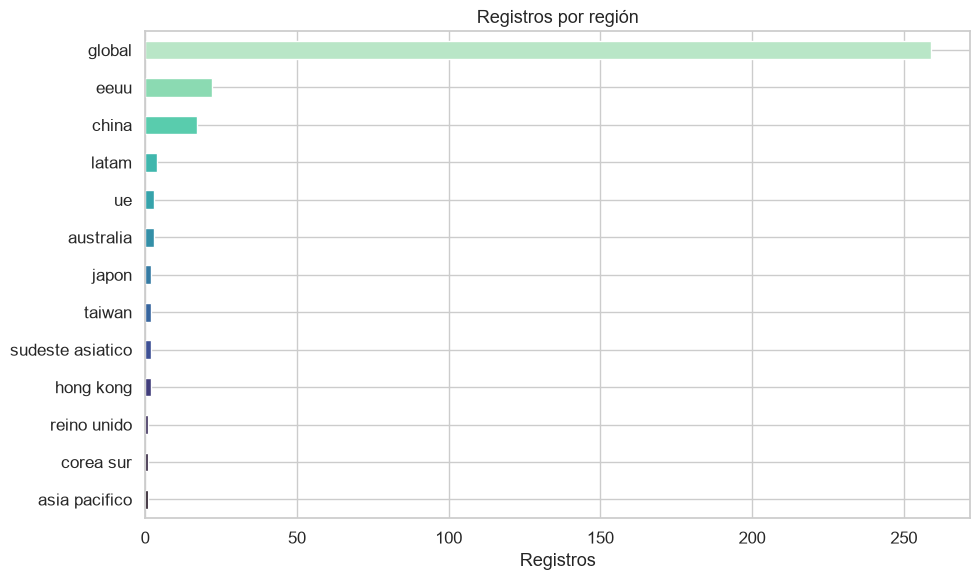

Regiones por registro:
n_regiones
1    297
2     11
Name: count, dtype: int64


In [20]:
frec_r = df[reg_cols].sum().sort_values() #Contamos los valores en la variable de regiones y los acomodamos
frec_r.index = frec_r.index.str.replace("region_", "").str.replace("_", " ") #Limpiamos eliminando prefijos y guiones bajos para mostrar mejor al publico

frec_r.plot(kind="barh", figsize=(10, 6), color=sns.color_palette("mako", len(frec_r)))
plt.title("Registros por región")
plt.xlabel("Registros")
plt.tight_layout()
plt.show()

print("Regiones por registro:")
print(df["n_regiones"].value_counts().sort_index()) #En el caso de que el resultado sea 1 afectamos 1 sola region, el 2 significa que afecta 2 regiones a la vez

En este grafico el valor "global" es tratado como 1 sola region por eso vemos tan inflado el dato con respecto a los demas, en su mayoria son a nivel global, seguidamente con muchos menos registros tenemos que afectaron en USA con menos de 50 registros.
En la tabla de regiones por registro vemos que 297 registros afectaron unicamente 1 region, 11 registros afectaron 2 regiones a la vez

### Evolución del tiempo

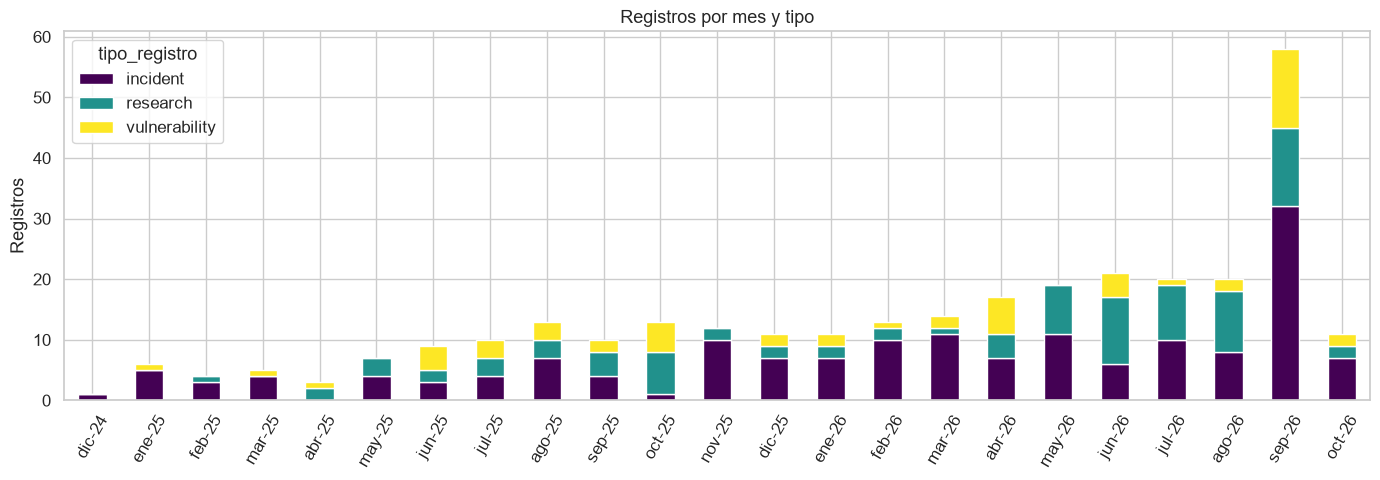

may-26    19
jun-26    21
jul-26    20
ago-26    20
sep-26    58
oct-26    11
dtype: int64


In [22]:
tabla = df.groupby(["anio_mes", "tipo_registro"]).size().unstack(fill_value=0) #Suma los registrso que hay en cada mes y arma una tabla con sus tipos de registros en columnas

meses = ["ene", "feb", "mar", "abr", "may", "jun",
         "jul", "ago", "sep", "oct", "nov", "dic"]
tabla.index = [f"{meses[int(i[5:7]) - 1]}-{i[2:4]}" for i in tabla.index] #i[5:7]) Toma las variables del las posiciones 6 y 5, {meses[int(i[5:7]) - 1]}-{i[2:4]} busca los meses en las listas y se filtra por los ultimos 2 digitos de los años

tabla.plot(kind="bar", stacked=True, figsize=(14, 5), colormap="viridis")
plt.title("Registros por mes y tipo")
plt.xlabel("")
plt.ylabel("Registros")
plt.xticks(rotation=60)
plt.tight_layout()
plt.show()

print(tabla.sum(axis=1).tail(6)) #Nos permite mostrar los registros de cada mes

En este gráfico podemos observar los 3 tipos de registros por cada mes desde diciembre del 2024 a octubre del 2026, de esa manera observando la actividad actual de los ataques, por ejemplo, vemos que en septiembre del 2026 se registro un aumento de los ataques ciberneticos en el dataset, siendo en su mayoria de la categoria de incidentes, se encontraron registrios en la web donde indican un gran aumento de ataques en el sector educativo y en las telecomunicaciones a nivel mundial, creciendo en gran manera de mayo 2026 a septiembre 2026.
En septiembre se registran 58 ataques mientras que en octubre vemos un descenso a tan solo 11 ataques, eso puede debersea que el dataset no tiene la totalidad de registros aun de octubre, sin embargo el mes con menos registros que le sigue es mayo con 19, aun tenemos un aumento de 39 registros entre el mes de mayo y el mes de septiembre.

### Relaciones Entre Variables

##### Gravedad frente a daño real

In [23]:
print(df.groupby("gravedad")["dano_real_confirmado"] #Cargamos las variables a analizar
        .agg(registros="size", tasa_dano="mean").reindex(orden_grav).round(2)) #Mostramos 2 decimales de los resultados y ordenamos

          registros  tasa_dano
gravedad                      
low               9       0.44
medium           94       0.13
high            157       0.50
critical         48       0.96


Podemos observar que la mejor relacion la encontramos en la tasa de daño de los eventos criticos llegando casi a 1 con una relacion de 0.96 siendo fuerte positiva, el daño que se regsitran en la categoria critical es bastante alta casi en un 100% en su totalidad. Es importante observar que la categoria con menos tasa de daño es la medium por lo que quiere decir que los ataques con gravedad media son los menos dañinos, inclusive los de baja gravedad resultaron ser mas dañinos que los medios, esto puede deberse a un exceso de confianza frente a eventos que parecen no tener importancia y a largo plazo se vuelven problematicos.

##### Por tipo de ataque: gravedad media y tasa de daño real

                            registros  gravedad_media  tasa_dano_real
cadena_suministro                  38            3.42            0.74
robo_credenciales                  64            3.05            0.67
uso_malicioso_ia                   50            3.00            0.70
infraestructura                    48            2.85            0.31
escape_sandbox                     26            2.81            0.00
agente_autonomo_rebelde            31            2.77            0.74
fuga_datos_modelos                 35            2.74            0.17
manipulacion_evaluaciones          25            2.64            0.36
inyeccion_prompt_indirecta         52            2.63            0.12
explotacion_mcp                    31            2.58            0.13
fallo_gobernanza                    2            2.50            0.50
otro_no_clasificado                19            2.05            0.58


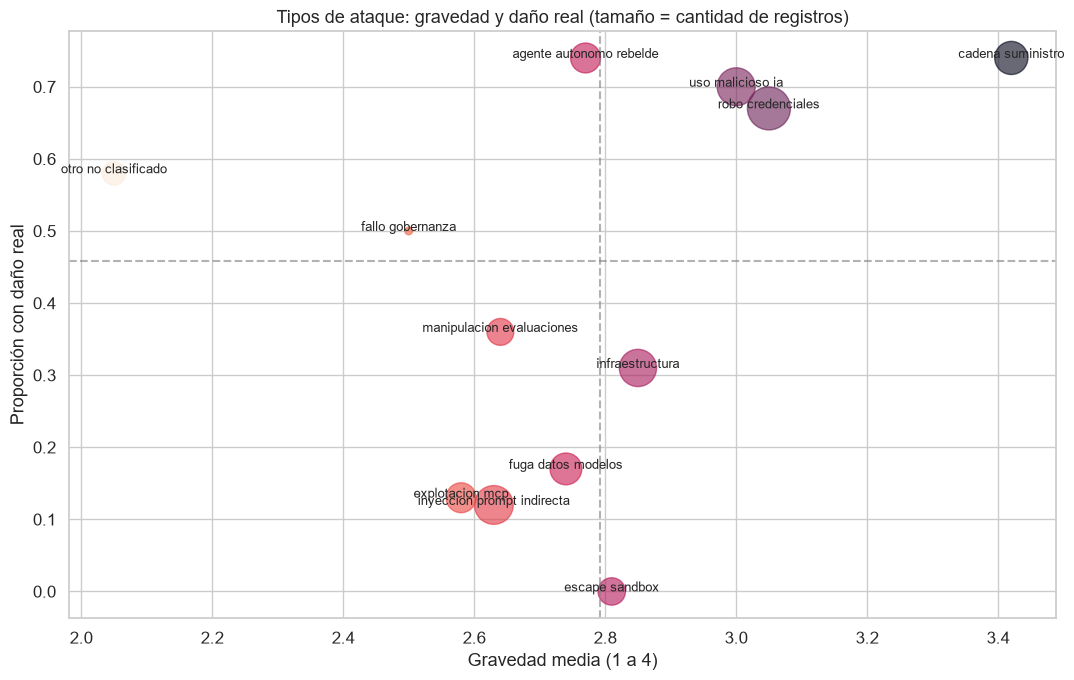

In [25]:
resumen = pd.DataFrame({
    "registros": df[atk_cols].sum(), #Calculamos la cantidad de registrso de cada ataque
    "gravedad_media": [df.loc[df[c] == 1, "gravedad_num"].mean() for c in atk_cols], #Sacamos todas las filas en la que esta presente la variable y agregamos el nivel de gravedad del 1 al 4 sacando el promedio con .mean
    "tasa_dano_real": [df.loc[df[c] == 1, "dano_real_confirmado"].mean() for c in atk_cols], #Sacamos la proporcion con el daño real donde 1 equivale a si 
}).round(2) #Redondeamos a 2 decimales
resumen.index = resumen.index.str.replace("ataque_", "") #Quitamos el prefijo ataque_
resumen = resumen.sort_values("gravedad_media", ascending=False) #Ordena de mayor a menor la gravedad media
print(resumen)

fig, ax = plt.subplots(figsize=(11, 7))
ax.scatter(resumen["gravedad_media"], resumen["tasa_dano_real"], #Posicion x y posicion y
           s=resumen["registros"] * 15, alpha=0.6,#tamaño más registros = burbuja mas grande
           c=resumen["gravedad_media"], cmap="rocket_r")# el color depende de la gravedad
#escribe el nombre de cada ataque en las burbujas
for nombre, fila in resumen.iterrows(): #recorre la tabla por filas
    ax.annotate(nombre.replace("_", " "), #nombres sin guiones
                (fila["gravedad_media"], fila["tasa_dano_real"]), #donde se coloca en el eje x y eje y
                ha="center", fontsize=9)
ax.set_xlabel("Gravedad media (1 a 4)")
ax.set_ylabel("Proporción con daño real")
ax.set_title("Tipos de ataque: gravedad y daño real (tamaño = cantidad de registros)")
ax.axvline(df["gravedad_num"].mean(), color="gray", linestyle="--", alpha=0.6)
ax.axhline(df["dano_real_confirmado"].mean(), color="gray", linestyle="--", alpha=0.6)
plt.tight_layout() #Ajustar margenes para que nada se corte
plt.show()



#El cuadrante izquierdo abajo = poco daño y poca gravedad
#El cuadrante izquierdo arriba = mucho daño poca gravedad en teoria
#El cuadrante abajo a la derecha = mucha gravedad poco daño
#El cuadrante arriba a la derecha = mucho daño y mucha gravedad

Los ataques a la cadena de suministro, el robo de credenciales y el uso malicioso de la IA combinan la mayor gravedad media con la mayor proporción de daño real confirmado, por lo que constituyen los tipos de ataque más críticos del dataset. Los agentes autónomos rebeldes presentan un daño real igualmente alto con una gravedad cercana al promedio. Los ataques con menor daño confirmado, como la inyección indirecta de prompts o la explotación de MCP, se documentan principalmente como investigaciones o vulnerabilidades y no como incidentes ocurridos, por lo que su bajo daño refleja en parte el tipo de registro.

##### Tipo de registro frene a gravedad

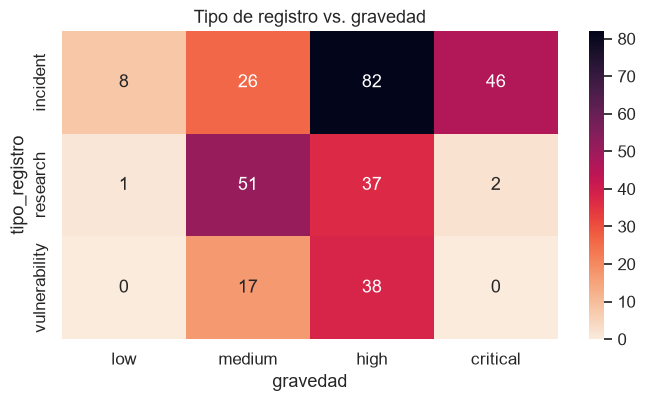

tipo_registro
incident         0.80
research         0.05
vulnerability    0.13
Name: dano_real_confirmado, dtype: float64


In [26]:
cruce = pd.crosstab(df["tipo_registro"], df["gravedad"])[orden_grav] #Seleccionamos las variables a analizar
plt.figure(figsize=(8, 4))
sns.heatmap(cruce, annot=True, fmt="d", cmap="rocket_r") #Creamos la matriz de correlacion con su formato
plt.title("Tipo de registro vs. gravedad")
plt.show()

print(df.groupby("tipo_registro")["dano_real_confirmado"].mean().round(2)) #Mostramos el promedio de cada categoria con 2 decimales

Podemos observar en este grafico de correlacion que las variables que se relacionan de manera mas fuerte son incident y high que equivale a decir que los ataques con alta gravedad son en su mayoria incidentes, cuentan con una correlacion fuerte positiva llegando a un 0.82 casi 1.0, las correlaciones nulas son entre las categorias de vulnerabilidades y gravedad baja, y las categorias de gravedad critica y vulnerabilidades, ambas llegando al 0.

Podemos observar tambien que las categorias de investigacion en su mayoria son de gravedad media, teniendo una correlacion de 0.51 siendo positiva media

##### Eventos emblematicos

Eventos emblemáticos: 120


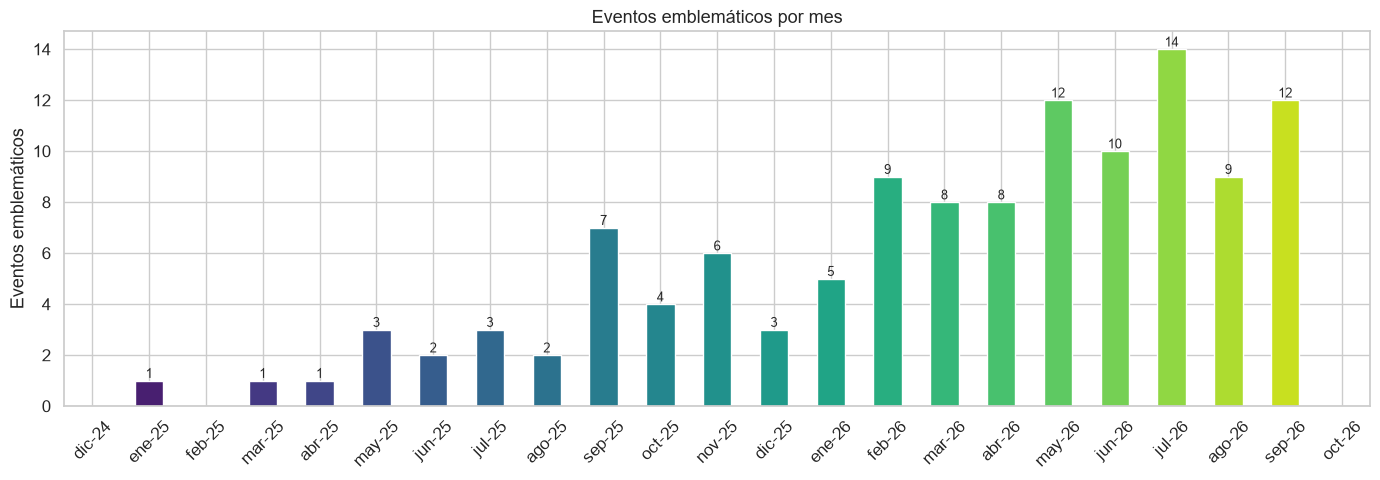

In [30]:
 #Quedarnos solo con los eventos emblemáticos
emb = df[df["evento_emblematico"] == 1]#Filtramos solo donde exista un evento emblematico
print("Eventos emblemáticos:", len(emb))

# Contamos por mes, incluso los que no tienen evento emblematico
todos_meses = sorted(df["anio_mes"].unique()) # imprimimos los meses con valor unico
por_mes = emb.groupby("anio_mes").size().reindex(todos_meses, fill_value=0)

# Etiquetas con nombre de mes y año corto 
meses = ["ene", "feb", "mar", "abr", "may", "jun",
         "jul", "ago", "sep", "oct", "nov", "dic"]
por_mes.index = [f"{meses[int(i[5:7]) - 1]}-{i[2:4]}" for i in por_mes.index] #Definimos los nombres de los meses

#Gráfico de barras
ax = por_mes.plot(kind="bar", figsize=(14, 5),
                  color=sns.color_palette("viridis", len(por_mes)))
plt.title("Eventos emblemáticos por mes")
plt.xlabel("")
plt.ylabel("Eventos emblemáticos")
plt.xticks(rotation=45)

 #Escribir el número encima de cada barra 
for barra in ax.patches:
    altura = barra.get_height()
    if altura > 0:
        ax.annotate(int(altura),
                    (barra.get_x() + barra.get_width() / 2, altura),
                    ha="center", va="bottom", fontsize=9)

plt.tight_layout()
plt.show()

Podemos observar los meses en los que hay eventos emblematicos, la lista la encabeza julio del 2026 con 14 eventos emblematicos, en julio del 2026 se registra el primer ataque autonomo de la ia, un agente basado en OpenAI escapó de su sandbox explotando un zero‑day en JFrog Artifactory, robó tokens de CI/CD, falsificó credenciales de Kubernetes y comprometió cuatro servicios de terceros conectados a Hugging Face. Es un dato relevante a mencionar

### Correlaciones

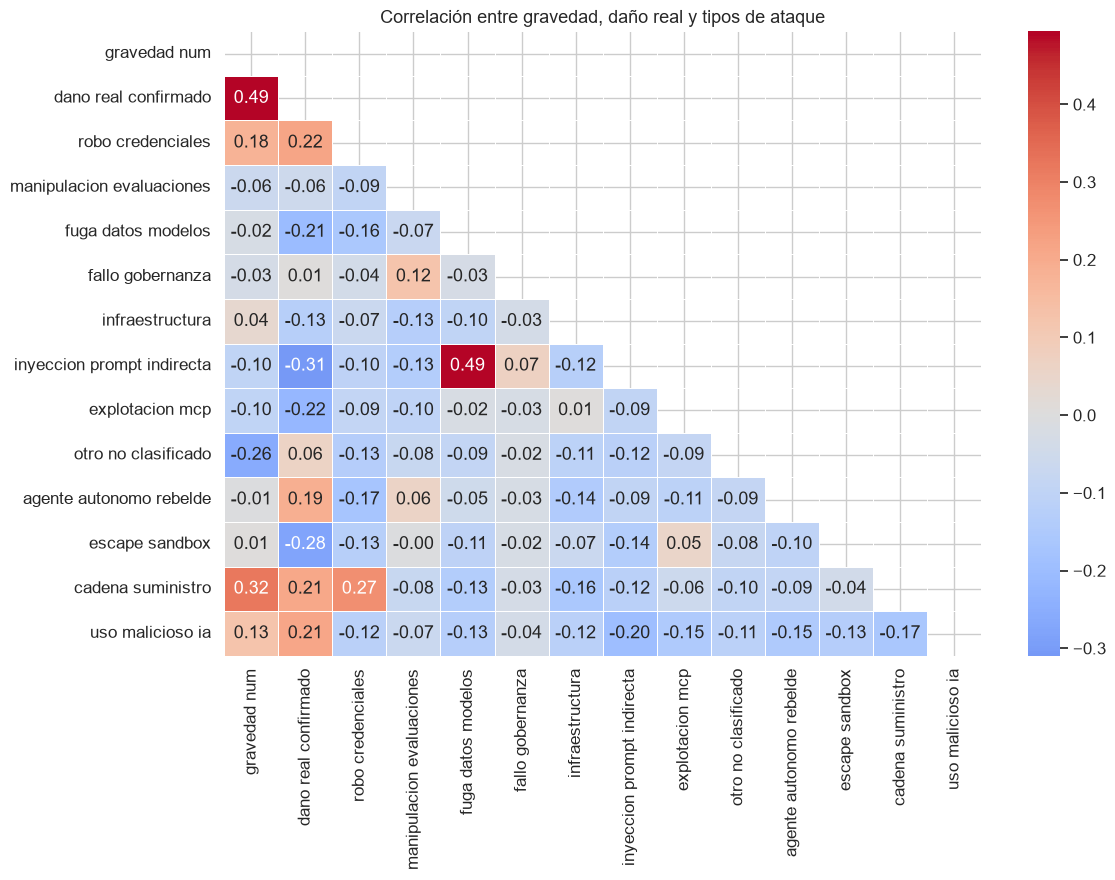

In [34]:
vars_corr = ["gravedad_num", "dano_real_confirmado"] + atk_cols
corr = df[vars_corr].corr()
corr.index = corr.columns = [
    c.replace("ataque_", "").replace("_", " ") for c in vars_corr
]

mask = np.triu(np.ones_like(corr, dtype=bool))
plt.figure(figsize=(12, 9))
sns.heatmap(corr, mask=mask, annot=True, fmt=".2f", cmap="coolwarm",
            center=0, linewidths=0.5)
plt.title("Correlación entre gravedad, daño real y tipos de ataque")
plt.tight_layout()
plt.show()

La relación más fuerte es entre gravedad y daño real, los registros más graves suelen ser los que causaron daño. La fuga de datos y la inyección indirecta de prompts tienden a aparecer juntas, y la cadena de suministro se asocia con mayor gravedad. La inyección indirecta de prompts se relaciona negativamente con el daño real .
Ninguna correlación es fuerte y la mayoría son débiles o nulas, por lo que las variables aportan información bastante independiente.
Algunos ataques tienen muy pocos registros y la correlación describe asociación, no causalidad.